<a href="https://colab.research.google.com/github/SasanduG/CV-Assignment-2/blob/main/EN3160_Assignment_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3160 Assignment 02


In [1]:
# Run once if required.
# %pip install numpy scipy matplotlib opencv-python pandas ipywidgets ipympl

In [19]:
from pathlib import Path
import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter
from scipy.optimize import minimize
from IPython.display import display

IMAGE_DIR = Path('images')
OUTPUT_DIR = Path('results_a02')
OUTPUT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (10, 6), 'axes.grid': False})

def read_image(path, flag=cv.IMREAD_COLOR):
    image = cv.imread(str(path), flag)
    if image is None:
        raise FileNotFoundError(f'Cannot read {path}. Set the image path to your downloaded file.')
    return image

def show_bgr(ax, image, title):
    ax.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')

## Question 1

In [22]:
SUNFLOWER_PATH = Path("/content/the_berry_farms_sunflower_field.jpeg")
SIGMAS = np.geomspace(2, 30, 30)  # Pixels in the reduced image; adjust after inspection.
RESPONSE_FRACTION = 0.12
MAX_OVERLAP = 0.35

# Scale-normalized negative LoG detects bright blobs.
def log_circles(image, sigmas, threshold_fraction=0.12, max_overlap=0.35):
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY).astype(np.float32) / 255
    responses = np.stack([-s*s*gaussian_laplace(gray, s) for s in sigmas])
    maxima = maximum_filter(responses, size=(3, 3, 3), mode='nearest')
    selected = (responses == maxima) & (responses > threshold_fraction * responses.max())
    # End scales cannot be verified as extrema along scale.
    selected[[0, -1]] = False
    candidates = []
    for k, y, x in np.argwhere(selected):
        radius = np.sqrt(2) * sigmas[k]
        if min(x, y, gray.shape[1]-1-x, gray.shape[0]-1-y) < radius:
            continue
        candidates.append((x, y, radius, sigmas[k], responses[k, y, x]))
    candidates.sort(key=lambda row: row[4], reverse=True)
    kept = []
    for candidate in candidates:
        x, y, radius, _, _ = candidate
        duplicate = False
        for xx, yy, rr, _, _ in kept:
            distance = np.hypot(x-xx, y-yy)
            if distance >= radius+rr:
                overlap = 0.
            elif distance <= abs(radius-rr):
                overlap = 1.
            else:
                a = np.arccos(np.clip((distance**2+radius**2-rr**2)/(2*distance*radius), -1, 1))
                d = np.arccos(np.clip((distance**2+rr**2-radius**2)/(2*distance*rr), -1, 1))
                area = radius**2*a + rr**2*d - .5*np.sqrt(max(0., (-distance+radius+rr)*(distance+radius-rr)*(distance-radius+rr)*(distance+radius+rr)))
                overlap = area/(np.pi*min(radius, rr)**2)
            if overlap > max_overlap:
                duplicate = True
                break
        if not duplicate:
            kept.append(candidate)
    return pd.DataFrame(kept, columns=['x', 'y', 'radius', 'sigma', 'response'])

Sigma range: 2.00 to 30.00 pixels; 30 scales
Detected circles: 266


,x,y,radius,sigma,response
133,28,64,22.067450,15.604044,0.145999
143,221,24,18.308064,12.945756,0.131431
223,287,19,13.834957,9.782792,0.064336
135,121,48,12.601520,8.910620,0.142983
236,51,198,11.478049,8.116206,0.055269
158,108,123,11.478049,8.116206,0.113713
213,72,323,10.454739,7.392617,0.069336
156,258,56,10.454739,7.392617,0.114849
173,286,189,8.673681,6.133219,0.097200
169,192,187,7.900391,5.586420,0.102479


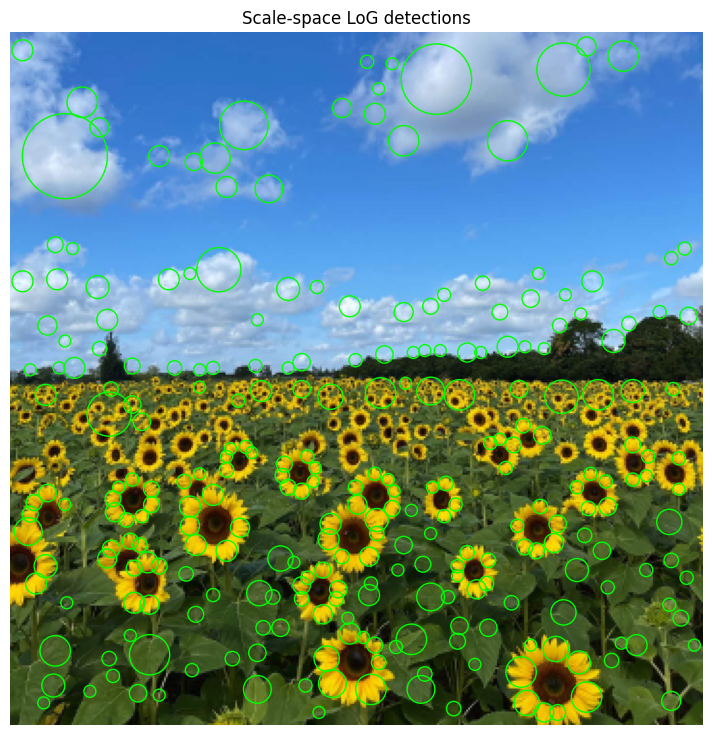

In [23]:
if SUNFLOWER_PATH.exists():
    sunflower = read_image(SUNFLOWER_PATH, cv.IMREAD_REDUCED_COLOR_4)
    circles = log_circles(sunflower, SIGMAS, RESPONSE_FRACTION, MAX_OVERLAP)
    print(f'Sigma range: {SIGMAS[0]:.2f} to {SIGMAS[-1]:.2f} pixels; {len(SIGMAS)} scales')
    print(f'Detected circles: {len(circles)}')
    display(circles.sort_values('radius', ascending=False).head(10))
    fig, ax = plt.subplots(figsize=(14, 9))
    show_bgr(ax, sunflower, 'Scale-space LoG detections')
    for row in circles.itertuples():
        ax.add_patch(plt.Circle((row.x, row.y), row.radius, fill=False, color='lime', linewidth=1))
    fig.savefig(OUTPUT_DIR / 'q1_circles.png', dpi=200, bbox_inches='tight')
    circles.to_csv(OUTPUT_DIR / 'q1_circle_parameters.csv', index=False)
    plt.show()
else:
    print(f'Add the supplied sunflower image at {SUNFLOWER_PATH} and rerun this cell.')

Coordinates, radii and $\sigma$ are in the reduced image. The relation $r=\sqrt{2}\sigma$ gives the characteristic LoG blob radius. Inspect the detections and tune the scale range and threshold; LoG also responds to other bright structures. Expand the scale range if the largest flowers lie near its boundary.

## Question 2

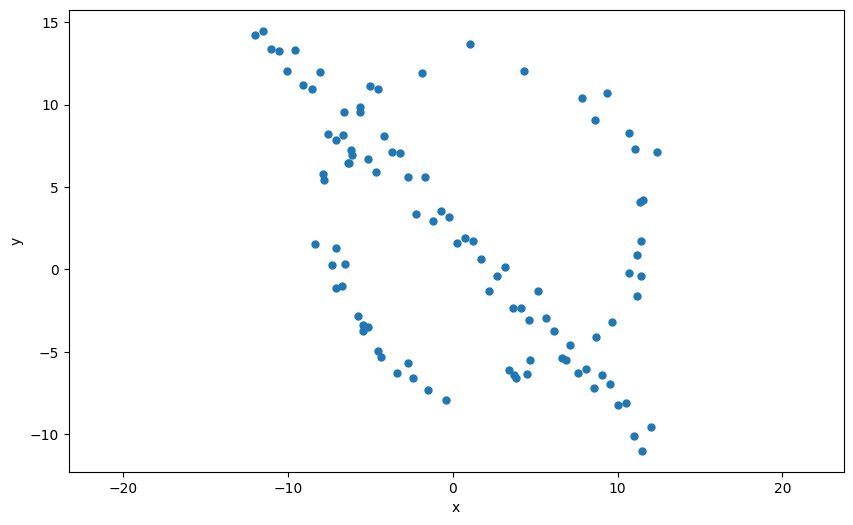

In [5]:
np.random.seed(0)
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3
s = r / 16
t = np.random.uniform(0, 2*np.pi, half_n)
noise = s * np.random.randn(half_n)
x = x0_gt + (r + noise)*np.cos(t)
y = y0_gt + (r + noise)*np.sin(t)
X_circ = np.column_stack((x, y))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + s*np.random.randn(half_n)
X_line = np.column_stack((x, y))
X = np.vstack((X_circ, X_line))
plt.scatter(X[:, 0], X[:, 1], s=25)
plt.axis('equal')
plt.xlabel('x'); plt.ylabel('y'); plt.show()

### (a)

In [6]:
def line_from_sample(points):
    v = points[1] - points[0]
    if np.linalg.norm(v) < 1e-10:
        return None
    normal = np.array([-v[1], v[0]]) / np.linalg.norm(v)
    d = normal @ points[0]
    if d < 0:
        normal, d = -normal, -d
    return np.r_[normal, d]

def line_error(points, model):
    return np.abs(points @ model[:2] - model[2])

def fit_line_tls(points):
    mean = points.mean(axis=0)
    _, _, vt = np.linalg.svd(points - mean, full_matrices=False)
    normal = vt[-1]
    d = normal @ mean
    if d < 0:
        normal, d = -normal, -d
    return np.r_[normal, d]

def ransac(points, sample_size, make_model, error, threshold, min_consensus, iterations, seed):
    rng = np.random.default_rng(seed)
    best, best_score = None, (-1, -np.inf)
    for _ in range(iterations):
        indices = rng.choice(len(points), sample_size, replace=False)
        model = make_model(points[indices])
        if model is None or not np.all(np.isfinite(model)):
            continue
        residuals = error(points, model)
        mask = residuals <= threshold
        count = int(mask.sum())
        if count < min_consensus:
            continue
        score = (count, -float(np.mean(residuals[mask]**2)))
        if score > best_score:
            best_score = score
            best = dict(sample_indices=indices.copy(), sample_model=model.copy(), inliers=mask.copy())
    if best is None:
        raise RuntimeError('No consensus found. Inspect the threshold and minimum consensus.')
    return best

LINE_THRESHOLD = 1.5
LINE_MIN_CONSENSUS = 35
ITERATIONS = 5000
line_result = ransac(X, 2, line_from_sample, line_error, LINE_THRESHOLD,
                     LINE_MIN_CONSENSUS, ITERATIONS, 10)
# Refit the winning consensus using total least squares.
line_inliers = line_result['inliers']
line_best = fit_line_tls(X[line_inliers])
a_hat, b_hat, d_hat = line_best
print(f'a={a_hat:.5f}, b={b_hat:.5f}, d={d_hat:.5f}')
print('Normal norm:', np.linalg.norm(line_best[:2]))
print('Consensus:', line_inliers.sum())
print('Refitted RMS distance:', np.sqrt(np.mean(line_error(X[line_inliers], line_best)**2)))

a=0.71565, b=0.69846, d=1.56177
Normal norm: 0.9999999999999999
Consensus: 57
Refitted RMS distance: 0.7581779147841622


The line is $ax+by=d$, with $a^2+b^2=1$ and $d\geq0$. For the generated line, the perpendicular noise standard deviation is $1/\sqrt{2}$. A distance threshold of 1.5 is approximately 2.1 standard deviations. At least 35 points must agree. With an inlier fraction of 0.35, 5000 trials comfortably exceed the trial count required for 99% probability of sampling two inliers. The consensus is retained from the winning RANSAC hypothesis and then refitted.

### (b)

In [7]:
def circle_from_sample(points):
    p0, p1, p2 = points
    A = 2*np.vstack((p1-p0, p2-p0))
    if np.linalg.cond(A) > 1e8:
        return None
    rhs = np.array([p1@p1-p0@p0, p2@p2-p0@p0])
    center = np.linalg.solve(A, rhs)
    return np.r_[center, np.linalg.norm(p0-center)]

def circle_error(points, model):
    return np.abs(np.linalg.norm(points-model[:2], axis=1) - model[2])

def refine_circle(points, initial):
    result = minimize(lambda p: np.sum(circle_error(points, p)**2), initial,
                      method='L-BFGS-B', bounds=[(None, None), (None, None), (1e-8, None)])
    if not result.success:
        raise RuntimeError(result.message)
    return result.x

remaining_indices = np.flatnonzero(~line_inliers)
remaining = X[remaining_indices]
CIRCLE_THRESHOLD = 1.4
CIRCLE_MIN_CONSENSUS = 25
circle_result = ransac(remaining, 3, circle_from_sample, circle_error,
                       CIRCLE_THRESHOLD, CIRCLE_MIN_CONSENSUS, ITERATIONS, 20)
circle_inliers = np.zeros(len(X), dtype=bool)
circle_inliers[remaining_indices[circle_result['inliers']]] = True
circle_best = refine_circle(X[circle_inliers], circle_result['sample_model'])
print('Circle center (x, y) and radius:', circle_best)
print('Consensus:', circle_inliers.sum())
print('Refitted RMS radial error:', np.sqrt(np.mean(circle_error(X[circle_inliers], circle_best)**2)))

Circle center (x, y) and radius: [1.86959007 3.06549701 9.94929249]
Consensus: 43
Refitted RMS radial error: 0.5738442972740614


The radial noise standard deviation is $10/16=0.625$. The threshold 1.4 is approximately 2.2 standard deviations. The minimum circle consensus is 25 because removing the line consensus also removes some circle points near the intersections. The optimizer minimizes squared radial distances on the winning consensus.

### (c)

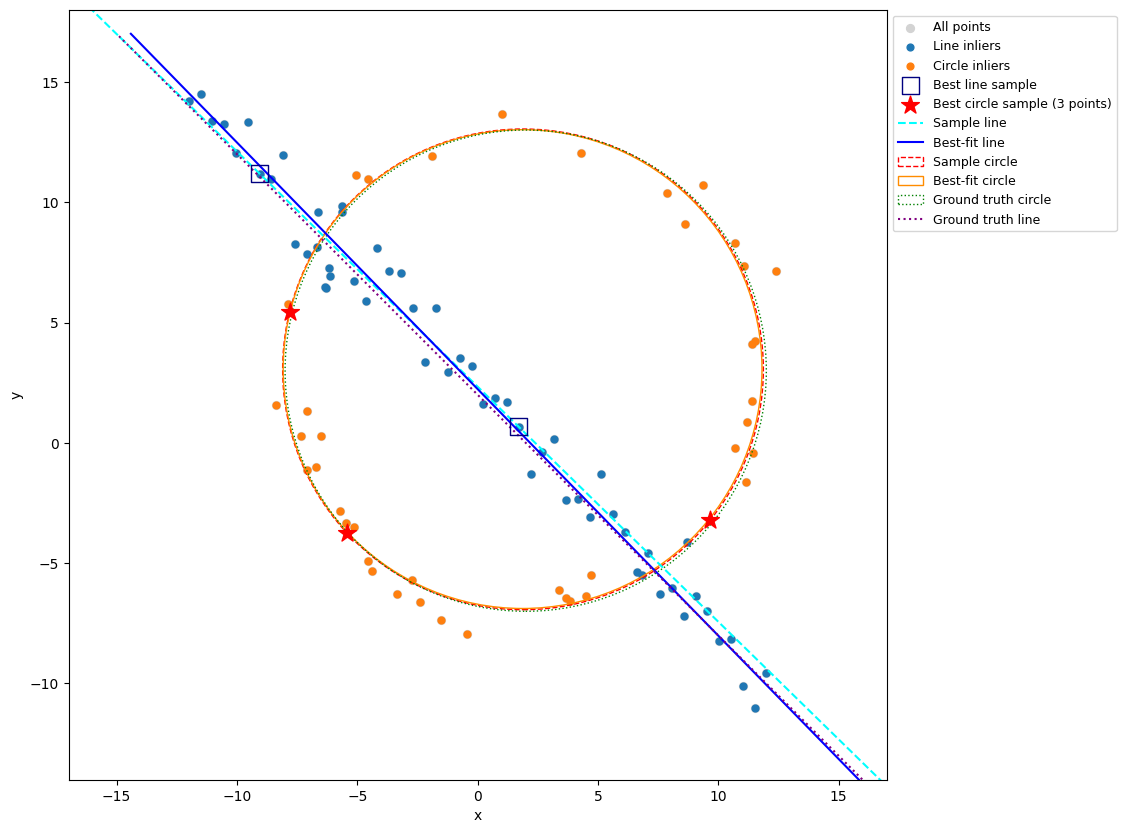

In [8]:
def draw_line(ax, model, **kwargs):
    a, b, d = model
    limits = np.array([-17., 17.])
    if abs(b) > abs(a):
        ax.plot(limits, (d-a*limits)/b, **kwargs)
    else:
        ax.plot((d-b*limits)/a, limits, **kwargs)

fig, ax = plt.subplots(figsize=(11, 10))
ax.scatter(*X.T, c='lightgray', label='All points', s=32)
ax.scatter(*X[line_inliers].T, color='tab:blue', label='Line inliers', s=24)
ax.scatter(*X[circle_inliers].T, color='tab:orange', label='Circle inliers', s=24)
ax.scatter(*X[line_result['sample_indices']].T, marker='s', facecolors='none', edgecolors='navy', s=150, label='Best line sample', zorder=5)
circle_sample = remaining[circle_result['sample_indices']]
ax.scatter(*circle_sample.T, marker='*', color='red', s=180, label='Best circle sample (3 points)', zorder=6)
draw_line(ax, line_result['sample_model'], color='cyan', linestyle='--', label='Sample line')
draw_line(ax, line_best, color='blue', label='Best-fit line')
for model, color, style, label in [(circle_result['sample_model'], 'red', '--', 'Sample circle'),
                                  (circle_best, 'darkorange', '-', 'Best-fit circle'),
                                  (np.array([2, 3, 10]), 'green', ':', 'Ground truth circle')]:
    ax.add_patch(plt.Circle(model[:2], model[2], fill=False, color=color, linestyle=style, label=label))
draw_line(ax, np.array([1, 1, 2])/np.sqrt(2), color='purple', linestyle=':', label='Ground truth line')
ax.set(xlim=(-17, 17), ylim=(-14, 18), xlabel='x', ylabel='y')
ax.set_aspect('equal'); ax.legend(fontsize=9, loc='upper left', bbox_to_anchor=(1, 1))
fig.savefig(OUTPUT_DIR / 'q2_ransac.png', dpi=200, bbox_inches='tight')
plt.show()

### (d)

Fitting the circle first can succeed, but a large-radius circle can approximate a line over a limited interval. Nearly collinear samples can therefore produce very large circles that gain consensus from the line points. Removing that consensus can damage the subsequent line fit. The outcome depends on noise, thresholds and sampling; failure is not guaranteed. Fitting the line first reduces this ambiguity. A justified radius bound or a collinearity test can also help.

In [9]:
circle_first = ransac(X, 3, circle_from_sample, circle_error,
                      CIRCLE_THRESHOLD, CIRCLE_MIN_CONSENSUS, ITERATIONS, 20)
first_model = refine_circle(X[circle_first['inliers']], circle_first['sample_model'])
print('Circle-first refitted model:', first_model)
print('Circle-first consensus:', circle_first['inliers'].sum())
print('True circle points in consensus:', circle_first['inliers'][:half_n].sum())
print('True line points in consensus:', circle_first['inliers'][half_n:].sum())

Circle-first refitted model: [1.94309523 3.00763992 9.92985375]
Circle-first consensus: 59
True circle points in consensus: 50
True line points in consensus: 9


## Question 3

Set two background/overlay pairs below. Select corners in order: top-left, top-right, bottom-right, bottom-left **as viewed on the overlay**. Use coordinates in each original background image. The optional click cell works with the interactive Matplotlib backend; manual coordinates work in both VS Code and Colab.

In [10]:
PAIRS = [
    {'background': IMAGE_DIR / 'building_1.jpg', 'overlay': IMAGE_DIR / 'flag_1.png', 'corners': None},
    {'background': IMAGE_DIR / 'building_2.jpg', 'overlay': IMAGE_DIR / 'flag_2.png', 'corners': None},
]
# Example syntax only: PAIRS[0]['corners'] = [[120, 80], [420, 95], [400, 300], [130, 280]]
ALPHA = 0.85

In [11]:
# Optional interactive corner selection. Set True and run this cell once per pair.
SELECT_CORNERS = False
PAIR_INDEX = 0
if SELECT_CORNERS:
    get_ipython().run_line_magic('matplotlib', 'widget')
    import ipywidgets as widgets
    background = read_image(PAIRS[PAIR_INDEX]['background'])
    chosen_pair = PAIRS[PAIR_INDEX]
    selected_points = []
    fig, ax = plt.subplots(figsize=(12, 8))
    show_bgr(ax, background, 'Click TL, TR, BR, BL; then run the warping cell')
    status = widgets.Output()
    display(status)
    def on_click(event):
        if event.inaxes != ax or len(selected_points) >= 4:
            return
        selected_points.append([float(event.xdata), float(event.ydata)])
        ax.plot(event.xdata, event.ydata, 'ro')
        ax.text(event.xdata, event.ydata, str(len(selected_points)), color='yellow')
        fig.canvas.draw_idle()
        if len(selected_points) == 4:
            chosen_pair['corners'] = selected_points.copy()
            with status:
                print('Saved corners:', selected_points)
            fig.canvas.mpl_disconnect(click_id)
    click_id = fig.canvas.mpl_connect('button_press_event', on_click)
    plt.show()

In [12]:
def place_overlay(background, overlay, corners, alpha=0.85):
    h, w = overlay.shape[:2]
    source = np.float32([[0, 0], [w-1, 0], [w-1, h-1], [0, h-1]])
    destination = np.float32(corners)
    if destination.shape != (4, 2) or not cv.isContourConvex(destination.reshape(-1, 1, 2)):
        raise ValueError('Provide four corners in cyclic order forming a convex quadrilateral.')
    H = cv.getPerspectiveTransform(source, destination)
    size = (background.shape[1], background.shape[0])
    if overlay.ndim == 2:
        overlay = cv.cvtColor(overlay, cv.COLOR_GRAY2BGR)
    opacity = overlay[:, :, 3].astype(np.float32)/255 if overlay.shape[2] == 4 else np.ones((h, w), np.float32)
    # Warp premultiplied color to avoid dark interpolation halos.
    color = overlay[:, :, :3].astype(np.float32)*opacity[:, :, None]
    warped = cv.warpPerspective(color, H, size)
    mask = cv.warpPerspective(opacity, H, size)[:, :, None]*alpha
    composite = background.astype(np.float32)*(1-mask) + alpha*warped
    return np.clip(composite, 0, 255).astype(np.uint8), H

for i, pair in enumerate(PAIRS, 1):
    if not pair['background'].exists() or not pair['overlay'].exists() or pair['corners'] is None:
        print(f'Pair {i}: set image paths and four corners before running.')
        continue
    background = read_image(pair['background'])
    overlay = read_image(pair['overlay'], cv.IMREAD_UNCHANGED)
    result, H = place_overlay(background, overlay, pair['corners'], ALPHA)
    fig, axes = plt.subplots(1, 2, figsize=(15, 7))
    show_bgr(axes[0], background, 'Background')
    show_bgr(axes[1], result, f'Pair {i}')
    cv.imwrite(str(OUTPUT_DIR / f'q3_pair_{i}.png'), result)
    print(f'Pair {i} homography:\n{H}')
    plt.show()

Pair 1: set image paths and four corners before running.
Pair 2: set image paths and four corners before running.


## Question 4

In [13]:
PCB_DIR = IMAGE_DIR / 'pcb'
TEMPLATE_PATH = PCB_DIR / 'AECC1.jpg'
RATIO_THRESHOLD = 0.75
REPROJECTION_THRESHOLD = 4.0

# (a)-(c)
def align_pcb(template, image):
    template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)
    image_gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    sift = cv.SIFT_create()
    kt, dt = sift.detectAndCompute(template_gray, None)
    ki, di = sift.detectAndCompute(image_gray, None)
    if dt is None or di is None or len(dt) < 2:
        raise ValueError('Insufficient SIFT descriptors.')
    matcher = cv.BFMatcher(cv.NORM_L2)
    pairs = matcher.knnMatch(di, dt, k=2)
    good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < RATIO_THRESHOLD*p[1].distance]
    if len(good) < 4:
        raise ValueError(f'Only {len(good)} matches passed the ratio test.')
    source = np.float32([ki[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    target = np.float32([kt[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv.findHomography(source, target, cv.RANSAC, REPROJECTION_THRESHOLD)
    if H is None or mask is None or mask.sum() < 4:
        raise ValueError('Homography estimation failed.')
    size = (template.shape[1], template.shape[0])
    aligned = cv.warpPerspective(image, H, size)
    support = cv.warpPerspective(np.ones(image.shape[:2], np.uint8)*255, H, size)
    valid = cv.erode((support == 255).astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)
    if not valid.any():
        raise ValueError('No valid overlap.')
    difference = cv.absdiff(template, aligned)
    difference[~valid] = 0
    matches = cv.drawMatches(image, ki, template, kt, good, None,
                             matchesMask=mask.ravel().tolist(),
                             flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    projected = cv.perspectiveTransform(source, H)
    inlier_errors = np.linalg.norm(projected-target, axis=2).ravel()[mask.ravel().astype(bool)]
    metrics = dict(matches=len(good), inliers=int(mask.sum()),
                   median_reprojection_error=float(np.median(inlier_errors)),
                   overlap_fraction=float(valid.mean()),
                   mean_absolute_difference=float(difference[valid].mean()))
    return aligned, difference, matches, valid, H, metrics

In [14]:
# (d)
summary = []
if TEMPLATE_PATH.exists():
    template = read_image(TEMPLATE_PATH)
    pcb_paths = sorted(p for p in PCB_DIR.iterdir()
                       if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}
                       and p.resolve() != TEMPLATE_PATH.resolve())
    if not pcb_paths:
        print('Add the other supplied PCB images to PCB_DIR.')
    for path in pcb_paths:
        try:
            image = read_image(path)
            aligned, difference, matches, valid, H, metrics = align_pcb(template, image)
            summary.append({'image': path.name, **metrics})
            fig, axes = plt.subplots(2, 2, figsize=(16, 12))
            show_bgr(axes[0, 0], matches, f'{path.name}: RANSAC inlier matches')
            show_bgr(axes[0, 1], aligned, 'Aligned image')
            show_bgr(axes[1, 0], template, 'Template')
            show_bgr(axes[1, 1], difference, 'Absolute difference (valid overlap only)')
            fig.tight_layout()
            fig.savefig(OUTPUT_DIR / f'q4_{path.stem}_comparison.png', dpi=150)
            cv.imwrite(str(OUTPUT_DIR / f'q4_{path.stem}_difference.png'), difference)
            cv.imwrite(str(OUTPUT_DIR / f'q4_{path.stem}_aligned.png'), aligned)
            cv.imwrite(str(OUTPUT_DIR / f'q4_{path.stem}_valid_mask.png'), valid.astype(np.uint8)*255)
            np.save(OUTPUT_DIR / f'q4_{path.stem}_homography.npy', H)
            plt.show()
        except (ValueError, cv.error, FileNotFoundError) as error:
            summary.append({'image': path.name, 'error': str(error)})
            print(path.name, ':', error)
    summary = pd.DataFrame(summary)
    display(summary)
    summary.to_csv(OUTPUT_DIR / 'q4_summary.csv', index=False)
else:
    print(f'Add the PCB images and set TEMPLATE_PATH. Current path: {TEMPLATE_PATH}')

Add the PCB images and set TEMPLATE_PATH. Current path: images/pcb/AECC1.jpg


### (e)

A single homography aligns points on the PCB plane. The USB Type B port, capacitors and reset button extend above this plane, so viewpoint changes produce parallax and they may remain misaligned after the board is aligned. Their appearance also changes through occlusion, shadows and reflections. Lighting, exposure, interpolation and imperfect feature localization contribute further differences. High difference values therefore do not necessarily indicate a defective or changed component. Black regions outside the valid warp overlap are excluded from the numerical comparison.